In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df_model = pd.read_excel("Cleaned_FINAL.xlsx")

In [17]:
data_ml = df_model.copy()

target_col = "NhomTrangThai"

# Các biến không dùng làm đầu vào
drop_cols = [
    "NgaySinh2",                 # Đã có biến Tuoi
    "CanhCaoHocVu_HK2",          # Thông tin HK2
    "DiemTBHocLuc_HK2",
    "XepLoaiHocLuc_HK2",
    "DiemTBTinChi_HK2",
    "STCDangKyHocKy_HK2",
    "SoTCKhongDat_HK2",
    "CoHocHK2",
    "CoHocHK3",
    "NghiHocHK1",                # Chỉ dùng để lọc dữ liệu

    # Loại các định danh nếu vẫn còn trong DataFrame
    "MaHoSo_TS",
    "IDSinhVien",
    "MaSinhVien",
    "Ten",
    "IDNganh",
    "IDLopHoc",
    "GhiChu",
    "TenTrangThai",
    "NamTotNghiep",
    "KhoaHoc",
    "NgayNhapHoc",


    #feature tốt
    "DiemHKDot1",
    #"CanhCaoHocVu_HK1",          # Thông tin HK2
    #"DiemTBHocLuc_HK1",
    #"XepLoaiHocLuc_HK1",
    #"DiemTBTinChi_HK1",
    #"STCDangKyHocKy_HK1",
    #"SoTCKhongDat_HK1",
    
]

# Chỉ giữ những dòng có nhãn mục tiêu hợp lệ
data_ml = data_ml[
    data_ml[target_col].isin([1, 2])
].copy()

y = data_ml[target_col].astype(int)

X = data_ml.drop(
    columns=[target_col] + drop_cols,
    errors="ignore"
).copy()

# KhoaHoc thể hiện các khóa riêng biệt, xử lý như biến phân loại
if "KhoaHoc" in X.columns:
    X["KhoaHoc"] = X["KhoaHoc"].astype("string")

print("Kích thước dữ liệu:", data_ml.shape)
print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

print("\nPhân bố nhãn:")
print(pd.DataFrame({
    "Số lượng": y.value_counts().sort_index(),
    "Tỷ lệ (%)": (
        y.value_counts(normalize=True).sort_index() * 100
    ).round(2)
}))

print("\nCác biến đầu vào:")
print(X.columns.tolist())

Kích thước dữ liệu: (21478, 39)
Kích thước X: (21478, 16)
Kích thước y: (21478,)

Phân bố nhãn:
               Số lượng  Tỷ lệ (%)
NhomTrangThai                     
1                 12207      56.83
2                  9271      43.17

Các biến đầu vào:
['DiemTongCong', 'GioiTinh', 'TenNganh', 'TenKhuVuc', 'TenTinh', 'TenHeDaoTao', 'TenLoaiHinhDT', 'DiemTBHocLuc_HK1', 'XepLoaiHocLuc_HK1', 'DiemTBTinChi_HK1', 'CanhCaoHocVu_HK1', 'STCDangKyHocKy_HK1', 'SoTCKhongDat_HK1', 'CoDiemThiTHPT', 'CoDiemUuTien', 'Tuoi']


In [18]:
summary = pd.DataFrame({
    "Data Type": X.dtypes.astype(str),
    "Non-Null": X.notna().sum(),
    "Null": X.isna().sum(),
    "Null (%)": (X.isna().mean() * 100).round(2),
    "Unique Values": X.nunique()
})

display(summary)

,Data Type,Non-Null,Null,Null (%),Unique Values
DiemTongCong,float64,20690,788,3.67,176
GioiTinh,bool,21478,0,0.00,2
TenNganh,str,21478,0,0.00,47
TenKhuVuc,str,21478,0,0.00,5
TenTinh,str,21478,0,0.00,66
TenHeDaoTao,str,21478,0,0.00,2
TenLoaiHinhDT,str,21478,0,0.00,12
DiemTBHocLuc_HK1,float64,21478,0,0.00,939
XepLoaiHocLuc_HK1,str,21478,0,0.00,7
DiemTBTinChi_HK1,float64,21478,0,0.00,374


In [19]:
from sklearn.model_selection import train_test_split

# Tách riêng 15% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=2026,
    stratify=y
)

# Tách phần còn lại thành 70% train và 15% validation
# 15 / 85 = khoảng 17.65% của phần còn lại
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=15/85,
    random_state=2026,
    stratify=y_train_val
)

# Kiểm tra số lượng và tỷ lệ các lớp
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}: {len(labels):,} quan sát")
    print(
        (labels.value_counts(normalize=True)
         .sort_index() * 100).round(2)
    )


Train: 15,034 quan sát
NhomTrangThai
1    56.84
2    43.16
Name: proportion, dtype: float64

Validation: 3,222 quan sát
NhomTrangThai
1    56.83
2    43.17
Name: proportion, dtype: float64

Test: 3,222 quan sát
NhomTrangThai
1    56.83
2    43.17
Name: proportion, dtype: float64


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Nhận diện kiểu dữ liệu dựa trên tập train
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Biến số:", numeric_cols)
print("\nBiến phân loại:", categorical_cols)


def create_preprocessor():
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(transformers=[
        ("num", numeric_pipeline, numeric_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

Biến số: ['DiemTongCong', 'DiemTBHocLuc_HK1', 'DiemTBTinChi_HK1', 'CanhCaoHocVu_HK1', 'STCDangKyHocKy_HK1', 'SoTCKhongDat_HK1', 'Tuoi']

Biến phân loại: ['GioiTinh', 'TenNganh', 'TenKhuVuc', 'TenTinh', 'TenHeDaoTao', 'TenLoaiHinhDT', 'XepLoaiHocLuc_HK1', 'CoDiemThiTHPT', 'CoDiemUuTien']


In [21]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
from scipy import sparse

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Chọn thiết bị huấn luyện
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Chuẩn bị dữ liệu: fit preprocessing chỉ trên Train
preprocessor_dl = create_preprocessor()

X_train_dl = preprocessor_dl.fit_transform(X_train)
X_val_dl = preprocessor_dl.transform(X_val)

# Chuyển dữ liệu sparse thành dense để đưa vào PyTorch
def to_dense_float32(X):
    if sparse.issparse(X):
        X = X.toarray()
    return np.asarray(X, dtype=np.float32)

X_train_dl = to_dense_float32(X_train_dl)
X_val_dl = to_dense_float32(X_val_dl)

# Mã hóa nhãn:
# 1 = Đã tốt nghiệp -> 0
# 2 = Thôi học / Tạm ngưng -> 1
y_train_dl = (np.asarray(y_train) == 2).astype(np.int64)
y_val_dl = (np.asarray(y_val) == 2).astype(np.int64)

input_dim = X_train_dl.shape[1]

print("Train:", X_train_dl.shape)
print("Validation:", X_val_dl.shape)
print("Số đặc trưng sau tiền xử lý:", input_dim)
print("Tỷ lệ lớp 2 trong Train:", round(y_train_dl.mean(), 3))

Device: cpu
Train: (15034, 152)
Validation: (3222, 152)
Số đặc trưng sau tiền xử lý: 152
Tỷ lệ lớp 2 trong Train: 0.432


In [22]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dims=(128, 64), dropout=0.2):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(prev_dim, hidden_dim),
                nn.BatchNorm1d(hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 2))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim, dropout=0.2):
        super().__init__()

        self.fc1 = nn.Linear(hidden_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        residual = x

        out = self.fc1(x)
        out = self.bn1(out)
        out = F.relu(out)
        out = self.dropout(out)

        out = self.fc2(out)
        out = self.bn2(out)

        return F.relu(out + residual)


class ResNetMLP(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dim=128,
        num_blocks=2,
        dropout=0.2
    ):
        super().__init__()

        self.input_layer = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU()
        )

        self.blocks = nn.Sequential(*[
            ResidualBlock(hidden_dim, dropout)
            for _ in range(num_blocks)
        ])

        self.output_layer = nn.Linear(hidden_dim, 2)

    def forward(self, x):
        x = self.input_layer(x)
        x = self.blocks(x)
        return self.output_layer(x)

In [23]:
def evaluate_dl(y_true, prob):
    pred = (prob >= 0.5).astype(int)

    return {
        "Val_Accuracy": accuracy_score(y_true, pred),
        "Val_Precision_Lop2": precision_score(
            y_true, pred, zero_division=0
        ),
        "Val_Recall_Lop2": recall_score(
            y_true, pred, zero_division=0
        ),
        "Val_F1_Lop2": f1_score(
            y_true, pred, zero_division=0
        ),
        "Val_ROC_AUC": roc_auc_score(y_true, prob)
    }


def train_torch_model(
    model,
    lr=1e-3,
    batch_size=256,
    weight_decay=1e-4,
    max_epochs=60,
    patience=8
):
    model = model.to(device)

    train_dataset = TensorDataset(
        torch.from_numpy(X_train_dl),
        torch.from_numpy(y_train_dl)
    )

    generator = torch.Generator().manual_seed(42)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    X_val_tensor = torch.from_numpy(X_val_dl).to(device)
    y_val_tensor = torch.from_numpy(y_val_dl).to(device)

    # Cân bằng trọng số hai lớp dựa trên Train
    counts = np.bincount(y_train_dl, minlength=2)
    weights = len(y_train_dl) / (2.0 * counts)

    class_weights = torch.tensor(
        weights, dtype=torch.float32, device=device
    )

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    history = {"train_loss": [], "val_loss": []}
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    for epoch in range(max_epochs):
        model.train()
        batch_losses = []

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())

        model.eval()

        with torch.no_grad():
            val_logits = model(X_val_tensor)
            val_loss = criterion(
                val_logits, y_val_tensor
            ).item()

        train_loss = float(np.mean(batch_losses))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # Lưu mô hình tại Validation Loss tốt nhất
        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            best_epoch = epoch + 1
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    model.eval()
    return model, history, best_epoch


def predict_torch_proba(model, X):
    model.eval()
    X_tensor = torch.from_numpy(X).to(device)

    with torch.no_grad():
        logits = model(X_tensor)
        prob = torch.softmax(logits, dim=1)[:, 1]

    return prob.cpu().numpy()

In [24]:
mlp_configs = [
    {
        "hidden_dims": (64, 32),
        "dropout": 0.2,
        "lr": 1e-3,
        "batch_size": 256
    },
    {
        "hidden_dims": (128, 64),
        "dropout": 0.3,
        "lr": 1e-3,
        "batch_size": 256
    },
    {
        "hidden_dims": (128, 64, 32),
        "dropout": 0.2,
        "lr": 5e-4,
        "batch_size": 128
    }
]

resnet_configs = [
    {
        "hidden_dim": 64,
        "num_blocks": 2,
        "dropout": 0.2,
        "lr": 1e-3,
        "batch_size": 256
    },
    {
        "hidden_dim": 128,
        "num_blocks": 2,
        "dropout": 0.2,
        "lr": 1e-3,
        "batch_size": 256
    },
    {
        "hidden_dim": 128,
        "num_blocks": 3,
        "dropout": 0.3,
        "lr": 5e-4,
        "batch_size": 128
    }
]

dl_results = []
dl_models = {}
dl_histories = {}


def run_torch_experiments(model_name, configs, builder):
    for i, config in enumerate(configs, start=1):
        set_seed(42)

        model = builder(config)

        trained_model, history, best_epoch = train_torch_model(
            model,
            lr=config["lr"],
            batch_size=config["batch_size"]
        )

        prob = predict_torch_proba(trained_model, X_val_dl)
        metrics = evaluate_dl(y_val_dl, prob)

        run_id = f"{model_name} - Config {i}"

        dl_results.append({
            "Model": model_name,
            "Run": run_id,
            "Config": str(config),
            "Best_Epoch": best_epoch,
            **metrics
        })

        dl_models[run_id] = trained_model
        dl_histories[run_id] = history

        print(
            f"{run_id}: "
            f"F1 lớp 2 = {metrics['Val_F1_Lop2']:.4f}"
        )


run_torch_experiments(
    "MLP",
    mlp_configs,
    lambda c: MLP(
        input_dim,
        hidden_dims=c["hidden_dims"],
        dropout=c["dropout"]
    )
)

run_torch_experiments(
    "ResNet-like MLP",
    resnet_configs,
    lambda c: ResNetMLP(
        input_dim,
        hidden_dim=c["hidden_dim"],
        num_blocks=c["num_blocks"],
        dropout=c["dropout"]
    )
)

MLP - Config 1: F1 lớp 2 = 0.7487
MLP - Config 2: F1 lớp 2 = 0.7488
MLP - Config 3: F1 lớp 2 = 0.7484
ResNet-like MLP - Config 1: F1 lớp 2 = 0.7515
ResNet-like MLP - Config 2: F1 lớp 2 = 0.7457
ResNet-like MLP - Config 3: F1 lớp 2 = 0.7502


In [25]:
from pytorch_tabnet.tab_model import TabNetClassifier

tabnet_configs = [
    {
        "n_d": 8,
        "n_a": 8,
        "n_steps": 3,
        "gamma": 1.3,
        "lr": 1e-3,
        "batch_size": 256
    },
    {
        "n_d": 16,
        "n_a": 16,
        "n_steps": 3,
        "gamma": 1.3,
        "lr": 1e-3,
        "batch_size": 256
    },
    {
        "n_d": 16,
        "n_a": 16,
        "n_steps": 4,
        "gamma": 1.5,
        "lr": 5e-4,
        "batch_size": 256
    }
]

for i, config in enumerate(tabnet_configs, start=1):
    print(f"Đang huấn luyện TabNet config {i}...")

    set_seed(42 + i)

    tabnet = TabNetClassifier(
        n_d=config["n_d"],
        n_a=config["n_a"],
        n_steps=config["n_steps"],
        gamma=config["gamma"],
        lambda_sparse=1e-4,
        optimizer_fn=torch.optim.Adam,
        optimizer_params={"lr": config["lr"]},
        seed=42 + i,
        verbose=0,
        device_name=device.type
    )

    tabnet.fit(
        X_train_dl,
        y_train_dl,
        eval_set=[(X_val_dl, y_val_dl)],
        eval_name=["valid"],
        eval_metric=["auc"],
        max_epochs=60,
        patience=10,
        batch_size=config["batch_size"],
        virtual_batch_size=128,
        num_workers=0,
        weights=1,
        drop_last=False
    )

    prob = tabnet.predict_proba(X_val_dl)[:, 1]
    metrics = evaluate_dl(y_val_dl, prob)

    run_id = f"TabNet - Config {i}"

    dl_results.append({
        "Model": "TabNet",
        "Run": run_id,
        "Config": str(config),
        "Best_Epoch": len(tabnet.history["loss"]),
        **metrics
    })

    dl_models[run_id] = tabnet

    # Lưu loss để vẽ đường cong huấn luyện
    dl_histories[run_id] = {
    "train_loss": list(tabnet.history["loss"]),
    "val_auc": list(tabnet.history["valid_auc"])
}

    print(
        f"{run_id}: "
        f"F1 lớp 2 = {metrics['Val_F1_Lop2']:.4f}"
    )

Đang huấn luyện TabNet config 1...
Stop training because you reached max_epochs = 60 with best_epoch = 53 and best_valid_auc = 0.84495


C:\Python\Python314\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


TabNet - Config 1: F1 lớp 2 = 0.7425
Đang huấn luyện TabNet config 2...

Early stopping occurred at epoch 38 with best_epoch = 28 and best_valid_auc = 0.84186


C:\Python\Python314\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


TabNet - Config 2: F1 lớp 2 = 0.7284
Đang huấn luyện TabNet config 3...

Early stopping occurred at epoch 59 with best_epoch = 49 and best_valid_auc = 0.82088


C:\Python\Python314\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


TabNet - Config 3: F1 lớp 2 = 0.7203


In [26]:
dl_results_df = pd.DataFrame(dl_results)

display(
    dl_results_df.sort_values(
        "Val_F1_Lop2",
        ascending=False
    ).round(4)
)

# Chọn cấu hình có F1-score lớp 2 cao nhất cho mỗi mô hình
best_dl_df = (
    dl_results_df.loc[
        dl_results_df.groupby("Model")["Val_F1_Lop2"].idxmax()
    ]
    .sort_values("Val_F1_Lop2", ascending=False)
    .reset_index(drop=True)
)

print("Cấu hình tốt nhất của từng mô hình:")
display(
    best_dl_df[
        [
            "Model", "Config", "Best_Epoch",
            "Val_Accuracy", "Val_Precision_Lop2",
            "Val_Recall_Lop2", "Val_F1_Lop2", "Val_ROC_AUC"
        ]
    ].round(4)
)

,Model,Run,Config,Best_Epoch,Val_Accuracy,Val_Precision_Lop2,Val_Recall_Lop2,Val_F1_Lop2,Val_ROC_AUC
3,ResNet-like MLP,ResNet-like MLP - Config 1,"{'hidden_dim': 64, 'num_blocks': 2, 'dropout':...",4,0.7945,0.7863,0.7196,0.7515,0.8627
5,ResNet-like MLP,ResNet-like MLP - Config 3,"{'hidden_dim': 128, 'num_blocks': 3, 'dropout'...",4,0.7939,0.7869,0.7168,0.7502,0.8593
1,MLP,MLP - Config 2,"{'hidden_dims': (128, 64), 'dropout': 0.3, 'lr...",6,0.7917,0.7812,0.7189,0.7488,0.8638
0,MLP,MLP - Config 1,"{'hidden_dims': (64, 32), 'dropout': 0.2, 'lr'...",5,0.7976,0.8071,0.6981,0.7487,0.8634
2,MLP,MLP - Config 3,"{'hidden_dims': (128, 64, 32), 'dropout': 0.2,...",5,0.7973,0.8065,0.6981,0.7484,0.8621
4,ResNet-like MLP,ResNet-like MLP - Config 2,"{'hidden_dim': 128, 'num_blocks': 2, 'dropout'...",2,0.7902,0.7822,0.7124,0.7457,0.8599
6,TabNet,TabNet - Config 1,"{'n_d': 8, 'n_a': 8, 'n_steps': 3, 'gamma': 1....",60,0.7871,0.7769,0.7110,0.7425,0.8450
7,TabNet,TabNet - Config 2,"{'n_d': 16, 'n_a': 16, 'n_steps': 3, 'gamma': ...",39,0.7815,0.7860,0.6786,0.7284,0.8419
8,TabNet,TabNet - Config 3,"{'n_d': 16, 'n_a': 16, 'n_steps': 4, 'gamma': ...",60,0.7821,0.8079,0.6499,0.7203,0.8209


Cấu hình tốt nhất của từng mô hình:


,Model,Config,Best_Epoch,Val_Accuracy,Val_Precision_Lop2,Val_Recall_Lop2,Val_F1_Lop2,Val_ROC_AUC
0,ResNet-like MLP,"{'hidden_dim': 64, 'num_blocks': 2, 'dropout':...",4,0.7945,0.7863,0.7196,0.7515,0.8627
1,MLP,"{'hidden_dims': (128, 64), 'dropout': 0.3, 'lr...",6,0.7917,0.7812,0.7189,0.7488,0.8638
2,TabNet,"{'n_d': 8, 'n_a': 8, 'n_steps': 3, 'gamma': 1....",60,0.7871,0.7769,0.7110,0.7425,0.8450


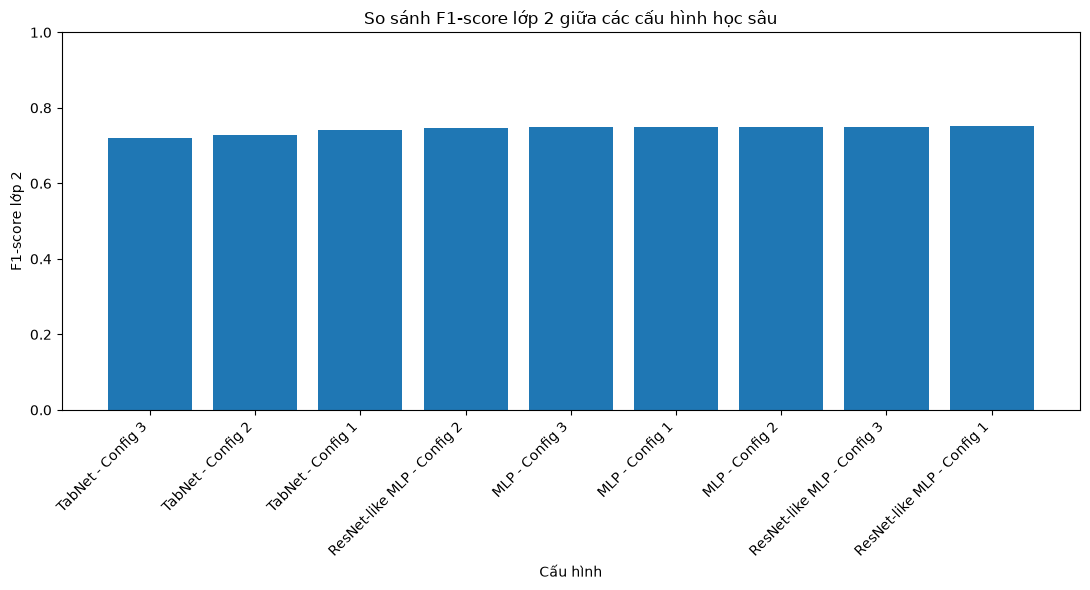

In [27]:
plot_df = dl_results_df.sort_values("Val_F1_Lop2")

plt.figure(figsize=(11, 6))
plt.bar(
    plot_df["Run"],
    plot_df["Val_F1_Lop2"]
)

plt.title("So sánh F1-score lớp 2 giữa các cấu hình học sâu")
plt.xlabel("Cấu hình")
plt.ylabel("F1-score lớp 2")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

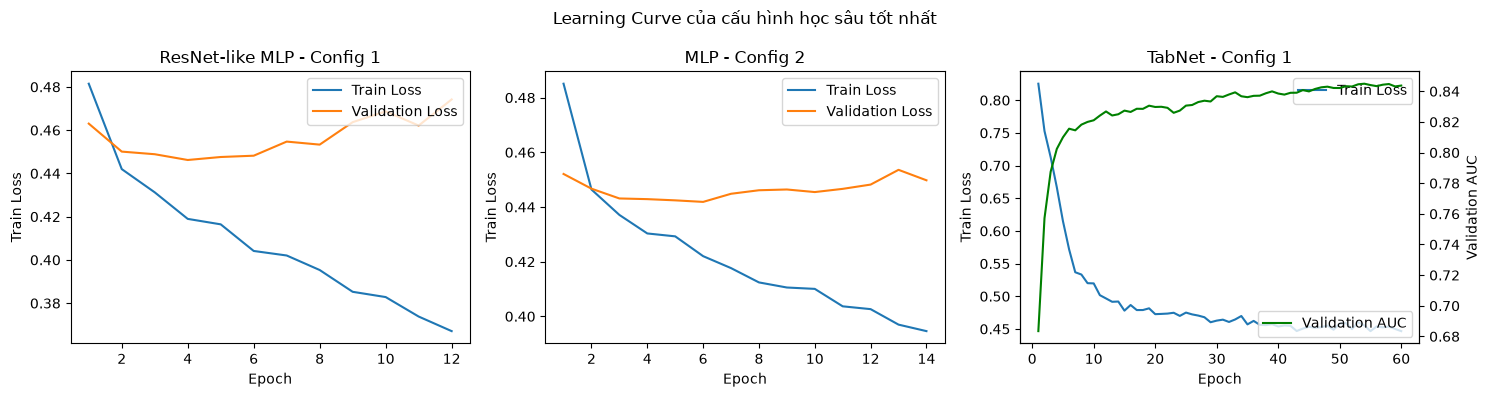

In [34]:
best_runs = best_dl_df["Run"].tolist()

fig, axes = plt.subplots(1, len(best_runs), figsize=(15, 4))

for ax, run_id in zip(axes, best_runs):
    history = dl_histories[run_id]

    epochs = range(1, len(history["train_loss"]) + 1)

    ax.plot(
        epochs,
        history["train_loss"],
        label="Train Loss"
    )

    # MLP và ResNet: vẽ Validation Loss
    if len(history.get("val_loss", [])) > 0:
        ax.plot(
            range(1, len(history["val_loss"]) + 1),
            history["val_loss"],
            label="Validation Loss"
        )

    # TabNet: vẽ Validation AUC trên trục Y thứ hai
    elif len(history.get("val_auc", [])) > 0:
        ax2 = ax.twinx()
        ax2.plot(
            range(1, len(history["val_auc"]) + 1),
            history["val_auc"],
            color="green",
            label="Validation AUC"
        )
        ax2.set_ylabel("Validation AUC")
        ax2.legend(loc="lower right")

    ax.set_title(run_id)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Train Loss")
    ax.legend(loc="upper right")

plt.suptitle("Learning Curve của cấu hình học sâu tốt nhất")
plt.tight_layout()
plt.show()

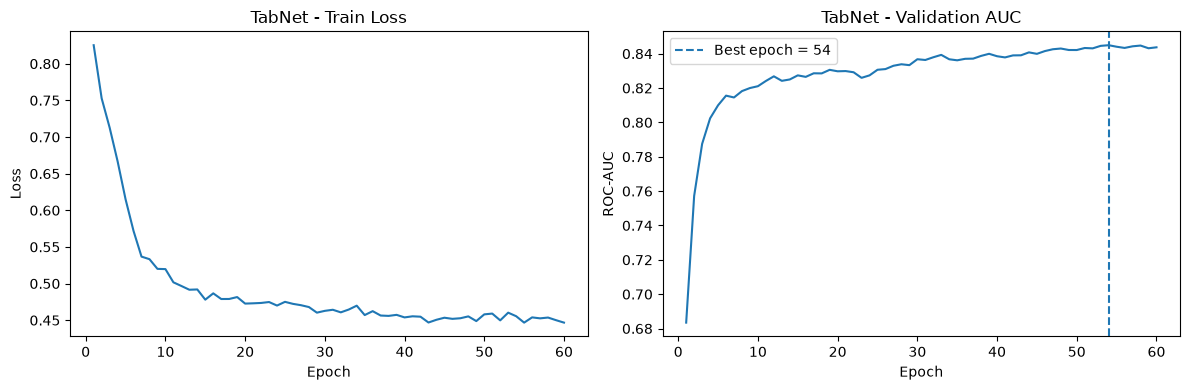

Best epoch: 54
Best Validation AUC: 0.84495


In [32]:
# Tìm cấu hình TabNet tốt nhất
tabnet_run = best_dl_df.loc[
    best_dl_df["Model"] == "TabNet", "Run"
].iloc[0]

history = dl_histories[tabnet_run]

train_loss = history["train_loss"]
val_auc = history["val_auc"]

epochs_loss = range(1, len(train_loss) + 1)
epochs_auc = range(1, len(val_auc) + 1)

best_auc_epoch = np.argmax(val_auc) + 1
best_auc = max(val_auc)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Train Loss
axes[0].plot(epochs_loss, train_loss)
axes[0].set_title("TabNet - Train Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

# Validation AUC
axes[1].plot(epochs_auc, val_auc)
axes[1].axvline(
    best_auc_epoch,
    linestyle="--",
    label=f"Best epoch = {best_auc_epoch}"
)
axes[1].set_title("TabNet - Validation AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("ROC-AUC")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Best epoch: {best_auc_epoch}")
print(f"Best Validation AUC: {best_auc:.5f}")

,Model,F1_Lop2,Recall_Lop2,ROC_AUC
0,Logistic Regression (ML),0.7426,0.6937,0.8587
1,Decision Tree (ML),0.7324,0.6751,0.8386
2,Random Forest (ML),0.7547,0.7045,0.8633
3,ResNet-like MLP (DL),0.7515,0.7196,0.8627
4,MLP (DL),0.7488,0.7189,0.8638
5,TabNet (DL),0.7425,0.7110,0.8450


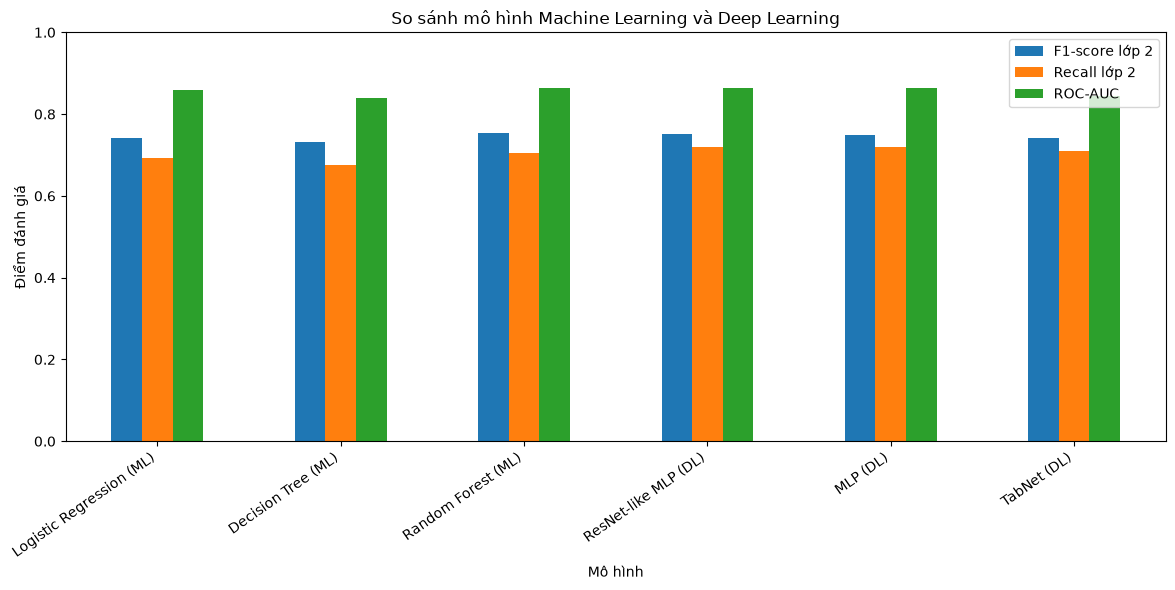

In [29]:
comparison_df = pd.read_excel("ComparisonDF.xlsx")

# Lấy kết quả ML đã tinh chỉnh trên Validation
ml_plot_df = (
    comparison_df[comparison_df["Stage"] == "Tuned"]
    [["Model", "F1_Lop2", "Recall_Lop2", "ROC_AUC"]]
    .copy()
)

ml_plot_df["Model"] = ml_plot_df["Model"] + " (ML)"

# Lấy cấu hình học sâu tốt nhất của từng họ mô hình
dl_plot_df = best_dl_df[
    ["Model", "Val_F1_Lop2", "Val_Recall_Lop2", "Val_ROC_AUC"]
].copy()

dl_plot_df = dl_plot_df.rename(columns={
    "Val_F1_Lop2": "F1_Lop2",
    "Val_Recall_Lop2": "Recall_Lop2",
    "Val_ROC_AUC": "ROC_AUC"
})

dl_plot_df["Model"] = dl_plot_df["Model"] + " (DL)"

all_compare_df = pd.concat(
    [ml_plot_df, dl_plot_df],
    ignore_index=True
)

display(all_compare_df.round(4))

all_compare_df.set_index("Model")[
    ["F1_Lop2", "Recall_Lop2", "ROC_AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("So sánh mô hình Machine Learning và Deep Learning")
plt.xlabel("Mô hình")
plt.ylabel("Điểm đánh giá")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.legend(["F1-score lớp 2", "Recall lớp 2", "ROC-AUC"])
plt.tight_layout()
plt.show()